# Cartagena in 1799
## Day 14 · Borgesian map · #30DayMapChallenge 2026

A detail of a small square in Cartagena’s historic centre from Juan José Ordovás’s 1799 plan, accompanied by the full plan and a photograph of the 1:700 physical model.

**Project by María Victoria León Parra**

Install requirements.txt and run all cells from this directory. The source images and the static Roboto Black face are included for an offline run.

## 1. Load the original references and typeface

Use the 1,972 × 1,218 original JPEG from the Wikimedia Commons file record. The model inset starts from the original 4,080 × 3,072 photograph by P4K1T0. Crop the top background so its frame matches the plan while keeping the historic centre visible. Bind the title and footer to the bundled Roboto Black file, and check the font’s OpenType metadata to confirm weight 900 before composing the page.

In [1]:
from io import BytesIO
from math import ceil, dist
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pymupdf
from fontTools.ttLib import TTFont
from IPython.display import Image as NotebookImage, display
from matplotlib import font_manager
from PIL import Image, ImageOps

DATA = Path("data")
OUT = Path("output")
OUT.mkdir(exist_ok=True)
MM_PER_INCH = 25.4

with Image.open(DATA / "Cartagena_Arsenal_1799.jpg") as source:
    assert source.size == (1972, 1218)
    plan = source.convert("RGB")
with Image.open(DATA / "Cartagena_model.jpg") as source:
    model = ImageOps.exif_transpose(source).convert("RGB")
    assert model.size == (4080, 3072)

# Keep the entire width and bottom of the photograph. The required height
# follows from the plan aspect ratio, so all trimming is at the top.
photo_height = model.width * plan.height / plan.width
photo_top = model.height - photo_height
# Sampling at the plan raster size preserves the aspect ratio on both axes.
model = model.transform(plan.size, Image.Transform.EXTENT,
                        (0, photo_top, model.width, model.height),
                        resample=Image.Resampling.BICUBIC)
print(f"Model reference: removed the top {photo_top:.1f} source pixels.")

# Resolve the exact static font file so system fonts cannot change the result.
font_path = (DATA / "Roboto-Black.ttf").resolve()
with TTFont(font_path) as font:
    assert font["OS/2"].usWeightClass == 900
    assert font["name"].getDebugName(6) == "Roboto-Black"
font_manager.fontManager.addfont(font_path)
black = font_manager.FontProperties(fname=font_path)
assert Path(font_manager.findfont(black, fallback_to_default=False)).resolve() == font_path
plt.rcParams["pdf.fonttype"] = 42  # Embed the TrueType subset and retain selectable text.
print("Matplotlib resolved Roboto-Black from the bundled static weight-900 font.")

Model reference: removed the top 552.0 source pixels.
Matplotlib resolved Roboto-Black from the bundled static weight-900 font.


## 2. Calibrate the plan from documented basin dimensions

Measure the short axis of the basin between the inner quay faces in source pixels and use the long axis as a separate check. Pixel coordinates increase rightward and downward. Use the short-axis estimate uniformly to preserve the scan's proportions. See the README for the calibration evidence and uncertainty.

In [2]:
across = ((573, 835), (870, 835))
along = ((690, 502), (690, 995))
px_per_m = dist(*across) / 318
check_px_per_m = dist(*along) / 550
difference_pct = 100 * abs(px_per_m - check_px_per_m) / px_per_m

print(f"Short axis {across}: {dist(*across):g} px / 318 m = {px_per_m:.4f} px/m.")
print(f"Long axis {along}: {dist(*along):g} px / 550 m = {check_px_per_m:.4f} px/m.")
print(f"Relative difference: {difference_pct:.1f}%.")

Short axis ((573, 835), (870, 835)): 297 px / 318 m = 0.9340 px/m.
Long axis ((690, 502), (690, 995)): 493 px / 550 m = 0.8964 px/m.
Relative difference: 4.0%.


## 3. Expand the historic-centre crop

Keep the centre of the plaza selected in the earlier comparison of three equal-size windows. At the nominal 1:700 target, the 280 mm panel represents 196 m. Recalculate the source bounds around that centre to bring more surrounding streets and blocks into view. Sample the new fractional square directly from the original scan with equal scaling on both axes.

In [3]:
PAGE_W_MM = 300
PANEL_MM = 280
MODEL_SCALE = 700
ground_side_m = PANEL_MM / 1000 * MODEL_SCALE
assert abs(ground_side_m - 196) < 1e-9

# Retain the previously selected plaza centre in the source pixel grid.
chosen = (1630, 506)
half = ground_side_m * px_per_m / 2
x, y = chosen
bounds = (x - half, y - half, x + half, y + half)
assert 0 <= bounds[0] < bounds[2] <= plan.width
assert 0 <= bounds[1] < bounds[3] <= plan.height

# Sample the enlarged window from the original rather than reusing the previous crop.
panel = plan.transform((2200, 2200), Image.Transform.EXTENT, bounds,
                       resample=Image.Resampling.BILINEAR)
print(f"Nominal ground extent: {ground_side_m:.0f} × {ground_side_m:.0f} m.")
print(f"Selected source bounds: {tuple(round(value, 2) for value in bounds)} px.")

Nominal ground extent: 196 × 196 m.
Selected source bounds: (1538.47, 414.47, 1721.53, 597.53) px.


## 4. Lay out the four elements

Follow Matplotlib’s [Figure size in different units](https://matplotlib.org/stable/gallery/subplots_axes_and_figures/figure_size_units.html) example. Convert the page dimensions from millimetres to inches for figsize. Position the map and references using their own millimetre rectangles, converted to figure fractions. Set the page height from the matched reference row and the vertical spacing. Reuse the same figure for both exports.

In [4]:
TITLE = "Day 14 | Cartagena in 1799"
FOOTER = "#30DayMapChallenge | 2026 | Day - 14 | Borgesian map | Cartagena in 1799 | Map by María Victoria León Parra"
PLAN_URL = "https://commons.wikimedia.org/wiki/File:Cartagena_Arsenal_1799.jpg"
MODEL_URL = "https://commons.wikimedia.org/wiki/File:Cartagena_y_su_Arsenal_durante_el_siglo_XVIII_(20221102_122219).jpg"
PAPER, INK = "#f3eddf", "#26342d"

map_left = (PAGE_W_MM - PANEL_MM) / 2
map_bottom = 12
reference_bottom = map_bottom + PANEL_MM + 12
reference_gap = 4
reference_width = (PANEL_MM - reference_gap) / 2
plan_h = reference_width * plan.height / plan.width
model_h = reference_width * model.height / model.width
reference_top = reference_bottom + max(plan_h, model_h)
title_pt = 30
title_gap = 4
top_margin = 6
PAGE_H_MM = ceil(reference_top + title_gap + title_pt * MM_PER_INCH / 72 + top_margin)

fig = plt.figure(figsize=(PAGE_W_MM / MM_PER_INCH, PAGE_H_MM / MM_PER_INCH),
                 facecolor=PAPER)


def place_image(image, x, y, width, height):
    # Equal-aspect axes keep the full image inside the specified physical rectangle.
    ax = fig.add_axes([x / PAGE_W_MM, y / PAGE_H_MM,
                       width / PAGE_W_MM, height / PAGE_H_MM])
    ax.imshow(image, interpolation="none", aspect="equal")
    ax.set_axis_off()
    return ax


def place_text(x, y, label, size, **style):
    return fig.text(x / PAGE_W_MM, y / PAGE_H_MM, label, color=INK,
                    fontsize=size, ha="center", **style)


place_text(PAGE_W_MM / 2, PAGE_H_MM - top_margin, TITLE, title_pt,
           fontproperties=black, va="top")
for image, x, height, label, credit, url in [
    (plan, map_left, plan_h, "Ordovás plan",
     "Juan José Ordovás · 1799 · Public domain", PLAN_URL),
    (model, map_left + reference_width + reference_gap, model_h, "Cartagena model (cropped)",
     "P4K1T0 · Wikimedia Commons · CC BY-SA 4.0", MODEL_URL),
]:
    place_image(image, x, reference_bottom, reference_width, height)
    place_text(x + reference_width / 2, reference_bottom - 2, label, 10, va="top")
    place_text(x + reference_width / 2, reference_bottom - 6.5, credit, 8,
               va="top", url=url)

place_image(panel, map_left, map_bottom, PANEL_MM, PANEL_MM)
place_text(PAGE_W_MM / 2, 6, FOOTER, 10, fontproperties=black, va="center");

Out[1]: Text(0.5, 0.014634146341463415, '#30DayMapChallenge | 2026 | Day - 14 | Borgesian map | Cartagena in 1799 | Map by María Victoria León Parra')


## 5. Export and inspect the saved geometry

Save the complete figure bounds. Read the PDF back to check the page dimensions, the main raster’s exact footprint and side margins, and the complete reference rasters. Check the title and footer text spans for font, point size and centring. Extract the embedded font subset and inspect its weight.

PDF page: 300.000 × 410.000 mm.
PDF map: 280.000 × 280.000 mm, with 10 mm side margins.
Verified the embedded Roboto Black weight-900 TrueType subset and both point sizes.


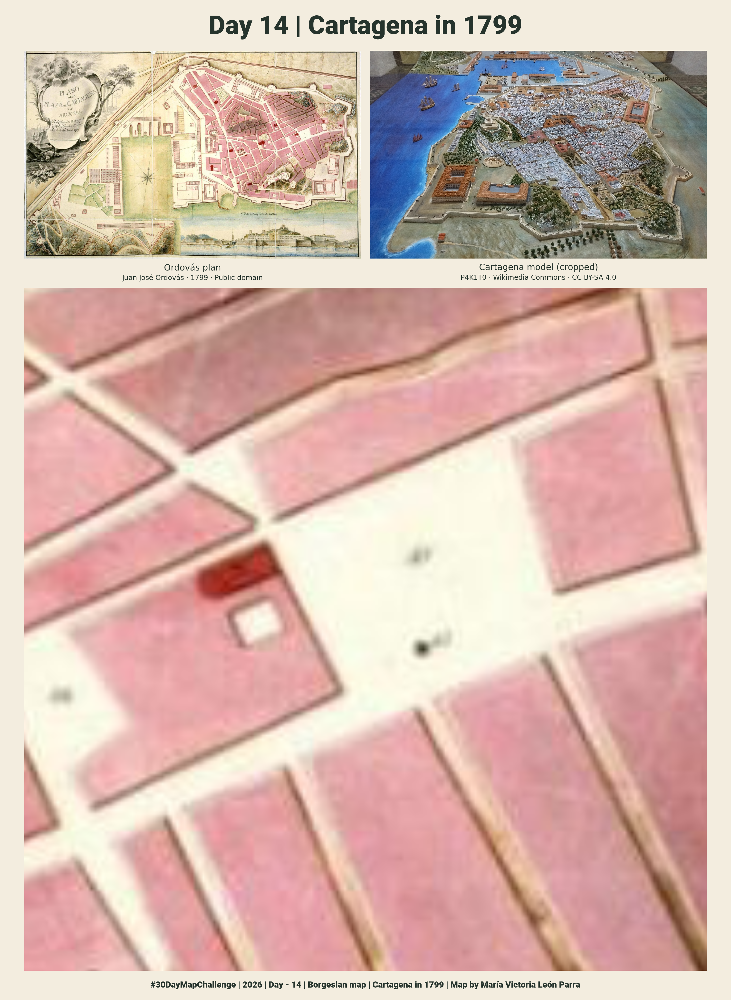

In [5]:
pdf_path = OUT / "day14_borgesian_map_print.pdf"
png_path = Path("linkedin.png")
fig.savefig(pdf_path, metadata={"Title": TITLE, "Author": "María Victoria León Parra"})
fig.savefig(png_path, dpi=254, metadata={"Title": TITLE})  # 10 pixels per millimetre.
plt.close(fig)

with Image.open(png_path) as image:
    assert image.size == (PAGE_W_MM * 10, PAGE_H_MM * 10)

points_to_mm = MM_PER_INCH / 72
with pymupdf.open(pdf_path) as document:
    page = document[0]
    page_mm = np.array([page.rect.width, page.rect.height]) * points_to_mm
    assert np.allclose(page_mm, [PAGE_W_MM, PAGE_H_MM], rtol=0, atol=.001)

    images = sorted(page.get_image_info(), key=lambda item: item["bbox"][0])
    assert len(images) == 3
    refs = [pymupdf.Rect(item["bbox"]) for item in images
            if (item["width"], item["height"]) == plan.size]
    assert len(refs) == 2
    for ref in refs:
        assert abs(ref.width / ref.height - plan.width / plan.height) < .0001
        assert page.rect.contains(ref)
    assert np.allclose([refs[0].y0, refs[0].y1], [refs[1].y0, refs[1].y1],
                       rtol=0, atol=.001)
    assert abs(refs[0].width - refs[1].width) < .001
    # The two references and their gap occupy the same width as the map.
    ref_margins = np.array([refs[0].x0, page.rect.width - refs[1].x1]) * points_to_mm
    assert np.allclose(ref_margins, [10, 10], rtol=0, atol=.001)
    main, = [pymupdf.Rect(item["bbox"]) for item in images
             if (item["width"], item["height"]) == panel.size]
    panel_mm = np.array([main.width, main.height]) * points_to_mm
    margins_mm = np.array([main.x0, page.rect.width - main.x1]) * points_to_mm
    assert np.allclose(panel_mm, [280, 280], rtol=0, atol=.001)
    assert np.allclose(margins_mm, [10, 10], rtol=0, atol=.001)

    spans = [span for block in page.get_text("dict", flags=pymupdf.TEXTFLAGS_TEXT)["blocks"]
             for line in block["lines"] for span in line["spans"]]
    for label, size in [(TITLE, 30), (FOOTER, 10)]:
        span, = [item for item in spans if item["text"] == label]
        assert span["font"].endswith("Roboto-Black")
        assert abs(span["size"] - size) < .001
        x0, _, x1, _ = span["bbox"]
        assert abs((x0 + x1) / 2 - page.rect.width / 2) < .4

    xref, = [item[0] for item in page.get_fonts() if item[3].endswith("Roboto-Black")]
    _, extension, _, font_bytes = document.extract_font(xref)
    assert extension == "ttf" and font_bytes
    with TTFont(BytesIO(font_bytes)) as embedded:
        assert embedded["OS/2"].usWeightClass == 900

print(f"PDF page: {page_mm[0]:.3f} × {page_mm[1]:.3f} mm.")
print(f"PDF map: {panel_mm[0]:.3f} × {panel_mm[1]:.3f} mm, with 10 mm side margins.")
print("Verified the embedded Roboto Black weight-900 TrueType subset and both point sizes.")
display(NotebookImage(filename=str(png_path), width=640))

## Sources and limitations

- **Plan:** Juan José Ordovás, *Plano de la plaza de Cartagena y su Arsenal* (1799), Archivo General Militar de Madrid, Cartoteca AT-161/27. [Public-domain Commons scan](https://commons.wikimedia.org/wiki/File:Cartagena_Arsenal_1799.jpg)
- **Calibration:** The Spanish Navy documents the basin’s 550 × 318 m dimensions. The municipal archive reproduction was also checked for the engraved scale. [Spanish Navy](https://armada.defensa.gob.es/ArmadaPortal/page/Portal/ArmadaEspannola/conocenosorganizacion/prefLang-es/04Apoyofuerza--02jal--05Arsenales--03arsenalcartagena) · [Municipal archive](https://archivo.cartagena.es/gestion/documentos/22601.pdf)
- **Model:** Ayuntamiento de Cartagena documents the 1:700 model. The reference photograph is by P4K1T0, CC BY-SA 4.0. [Municipal documentation](https://www.cartagena.es/detalle_noticias.asp?id=37021) · [Photograph](https://commons.wikimedia.org/wiki/File:Cartagena_y_su_Arsenal_durante_el_siglo_XVIII_(20221102_122219).jpg) · [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/)
- **Typography and layout:** [Google’s Roboto Black](https://github.com/googlefonts/roboto/blob/main/src/hinted/Roboto-Black.ttf), Apache 2.0, and [Matplotlib’s Figure size in different units](https://matplotlib.org/stable/gallery/subplots_axes_and_figures/figure_size_units.html).